<a href="https://colab.research.google.com/github/Riccardo-27/DL-Quantum/blob/dev-ernesto/notebooks/02_windowing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 – Finestrature Temporali, Allineamento Target e Super-Risoluzione
### Preparazione delle Coppie Input-Target per l'Addestramento dei Modelli

---

## 📌 Ruolo di Questo Notebook nella Pipeline

Nel primo notebook abbiamo pulito il dataset, verificato la fisica del sistema e congelato lo split per traiettoria (280 Train, 60 Val, 60 Test).
Tuttavia, i modelli di Deep Learning sequenziali (LSTM, GRU, Transformer) non possono essere addestrati direttamente su intere traiettorie lunghe 1001 passi: hanno bisogno di essere alimentati con **coppie (Input, Target)** generate tramite una **finestra temporale scorrevole (*sliding window*)**.

In questo notebook definiamo e verifichiamo la logica di finestratura condivisa che alimenterà tutti i modelli del progetto:

1. **Finestrature Standard di Progetto (`short` e `long`)**:
   - `short`: $T_{in} = 10$ passi ($0.20$ unità temporali) $\to T_{out} = 40$ passi ($0.80$ unità temporali);
   - `long`: $T_{in} = 20$ passi ($0.40$ unità temporali) $\to T_{out} = 40$ passi ($0.80$ unità temporali);
   - Stride di scorrimento fisso $\Delta s = 10$.

2. **Griglia $T_{in} \in \{5, 10, 20, 40\}$ per la Sfida 1 (Finestra Minima)**:
   - Cerchiamo la finestra di osservazione minima necessaria al modello per fare previsioni affidabili.
   - **Allineamento dei Target (`align_t_in = 40`)**: allineiamo matematicamente l'inizio delle previsioni in modo che tutti i modelli valutino esattamente gli stessi istanti futuri $Y$.

3. **Finestre per la Sfida 2 (Super-Risoluzione Temporale)**:
   - Sottocampioniamo l'input nel tempo ($\Delta t = 0.04$, frequenza dimezzata) per chiedere alla rete di ricostruire il futuro a piena risoluzione ($\Delta t = 0.02$).

4. **Input per il Decoder ($Y_{dec}$) e Teacher Forcing**:
   - Creiamo il target shiftato a destra necessario per l'addestramento dei modelli Sequenza-a-Sequenza e Transformer.

5. **Garanzie Assolute Anti-Leakage**:
   - Verifichiamo che nessuna finestra oltrepassi i confini tra traiettorie diverse e che Train, Val e Test rimangano disgiunti al 100%.

6. **Efficienza in RAM**:
   - Dimostriamo che generare le finestre al volo in memoria con `sliding_window_view` richiede meno di 0.4 secondi, evitando di sprecare gigabyte su disco.


## 0. Setup dell'Ambiente e Gestione Multi-Utente

Rilevamento automatico dell'ambiente di lavoro (Google Colab con Drive vs ambiente locale su PC).
In base al segreto Colab configurato nell'icona 🔑 a sinistra:
- **`GIT_E_TOKEN`**: configura automaticamente **Ernesto** e lavora sul branch **`dev-ernesto`**.
- **`GIT_R_TOKEN`**: configura automaticamente **Riccardo** e lavora sul branch **`dev-riccardo`**.

Imposta inoltre il seme globale (`SEED = 42`), garantisce l'allineamento automatico (`pull --rebase --autostash`) e verifica la GPU.


In [1]:
# =============================================================================
# 0. Setup Ambiente, Rilevamento Autore da Segreto Colab e Sincronizzazione Git
# =============================================================================
import os
import sys
import time
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

AUTHOR = None
CURRENT_BRANCH = None
GIT_TOKEN = None
AUTHOR_NAME = None
AUTHOR_EMAIL = None

if IN_COLAB:
    from google.colab import drive, userdata
    drive.mount("/content/drive")

    DRIVE_REPO = Path("/content/drive/MyDrive/DL-Quantum")
    LOCAL_REPO = Path("/content/DL-Quantum")

    if (DRIVE_REPO / "src" / "seeding.py").exists():
        REPO_PATH = DRIVE_REPO
    elif (LOCAL_REPO / "src" / "seeding.py").exists():
        REPO_PATH = LOCAL_REPO
    elif DRIVE_REPO.exists():
        !git -C /content/drive/MyDrive/DL-Quantum fetch origin
        REPO_PATH = DRIVE_REPO
    else:
        print("Clonazione automatica del repository su Google Drive...")
        !git clone https://github.com/Riccardo-27/DL-Quantum.git /content/drive/MyDrive/DL-Quantum
        REPO_PATH = DRIVE_REPO

    # 1. Rilevamento automatico dell'Autore dai Segreti di Colab (icona 🔑)
    # - Ernesto: imposta GIT_E_TOKEN nei propri Secret -> dev-ernesto
    # - Riccardo: imposta GIT_R_TOKEN nei propri Secret -> dev-riccardo
    try:
        GIT_TOKEN = userdata.get("GIT_E_TOKEN")
        if GIT_TOKEN:
            AUTHOR = "ernesto"
            CURRENT_BRANCH = "dev-ernesto"
            AUTHOR_NAME = "Ernesto Gligora"
            AUTHOR_EMAIL = "ernestogligora2003@gmail.com"
    except Exception:
        pass

    if not GIT_TOKEN:
        try:
            GIT_TOKEN = userdata.get("GIT_R_TOKEN")
            if GIT_TOKEN:
                AUTHOR = "riccardo"
                CURRENT_BRANCH = "dev-riccardo"
                AUTHOR_NAME = "Riccardo Lavorato"
                AUTHOR_EMAIL = "lavoratoriccardo@gmail.com"
        except Exception:
            pass

    # Fallback su chiave generica GH_TOKEN se presente
    if not GIT_TOKEN:
        for k in ("GH_TOKEN", "GITHUB_TOKEN"):
            try:
                t = userdata.get(k)
                if t:
                    GIT_TOKEN = t
                    break
            except Exception:
                pass
else:
    # Ambiente Locale
    REPO_PATH = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

# Fallback se non rilevato dai segreti Colab (es. esecuzione locale da terminale)
if not CURRENT_BRANCH:
    b_check = !git -C "{REPO_PATH}" branch --show-current
    CURRENT_BRANCH = b_check[0].strip() if b_check and b_check[0].strip() else "dev-ernesto"

if not AUTHOR:
    if "riccardo" in CURRENT_BRANCH.lower():
        AUTHOR = "riccardo"
        AUTHOR_NAME = "Riccardo Lavorato"
        AUTHOR_EMAIL = "lavoratoriccardo@gmail.com"
    else:
        AUTHOR = "ernesto"
        AUTHOR_NAME = "Ernesto Gligora"
        AUTHOR_EMAIL = "ernestogligora2003@gmail.com"

# Su Colab, allineamento automatico sul branch corrispondente all'autore rilevato
if IN_COLAB:
    print(f"Allineamento automatico sul branch '{CURRENT_BRANCH}' per {AUTHOR_NAME}...")
    !git -C "{REPO_PATH}" config user.name "{AUTHOR_NAME}"
    !git -C "{REPO_PATH}" config user.email "{AUTHOR_EMAIL}"
    !git -C "{REPO_PATH}" fetch origin
    !git -C "{REPO_PATH}" checkout -f {CURRENT_BRANCH}
    !git -C "{REPO_PATH}" pull --rebase --autostash origin {CURRENT_BRANCH}

# Configurazione variabili d'ambiente e path dei moduli src/
os.environ["DLQ_AUTHOR"] = AUTHOR
os.environ["DLQ_ROOT"] = str(REPO_PATH)

if str(REPO_PATH) not in sys.path:
    sys.path.insert(0, str(REPO_PATH))

# Inizializzazione rigorosa dei seed per determinismo numerico
from src.seeding import set_seeds
SEED = 42
set_seeds(SEED)

try:
    import tensorflow as tf
    print("TensorFlow:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))
except ImportError:
    print("TensorFlow non rilevato nell'ambiente locale")

token_status = "Rilevato ✔" if GIT_TOKEN else "Non impostato (crea segreto GIT_E_TOKEN o GIT_R_TOKEN per push automatico)"
print(f"\n✔ Ambiente inizializzato con successo!")
print(f"  • Autore attivo: {AUTHOR_NAME} ({token_status})")
print(f"  • Branch Git: {CURRENT_BRANCH}")
print(f"  • Root cartella: {REPO_PATH}")



Mounted at /content/drive
Allineamento automatico sul branch 'dev-ernesto' per Ernesto Gligora...
remote: Enumerating objects: 18, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 12 (delta 6), reused 8 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (12/12), 17.34 KiB | 11.00 KiB/s, done.
From https://github.com/Riccardo-27/DL-Quantum
   e5d6c48..bf5689a  dev-ernesto -> origin/dev-ernesto
Updating files: 100% (32/32), done.
Already on 'dev-ernesto'
Your branch is behind 'origin/dev-ernesto' by 3 commits, and can be fast-forwarded.
  (use "git pull" to update your local branch)
From https://github.com/Riccardo-27/DL-Quantum
 * branch            dev-ernesto -> FETCH_HEAD
Updating f2803d4..bf5689a
Fast-forward
 notebooks/01_data.ipynb                 | 5783 ++++++++++++++++---------------
 notebooks/02_windowing.ipynb            |  125 +-
 results/01_data_results.md              |  135 +-
 results/s2_normalization_

In [2]:
# =============================================================================
# Import Moduli di Progetto e Configurazione Percorsi
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import (
    DT, N_FEATURES, N_POINTS, N_QUBITS, N_TRAJ, get_paths, make_config
)
from src.data import feature_names, load_split, load_trajectories
from src.plots import plot_window, save_figure
from src.windowing import (
    check_no_leakage, decoder_inputs, make_sr_windows,
    make_windows, target_time_index, window_starts
)

CFG = make_config()
PATHS = get_paths()
NAMES = feature_names()

print("Configurazione predefinita caricata:")
print(f"  Orizzonte futuro (T_out)    : {CFG['t_out']} passi ({CFG['t_out']*DT:.2f} unita' fisiche)")
print(f"  Passo di scorrimento (stride): {CFG['stride']} passi ({CFG['stride']*DT:.2f} unita' fisiche)")
print(f"  Finestre standard           : {CFG['windows']}")
print(f"  Griglia Sfida 1 (T_in_grid) : {CFG['t_in_grid']}")
print(f"  Fattore Super-Risoluzione   : x{CFG['sr_factor']}")


Configurazione predefinita caricata:
  Orizzonte futuro (T_out)    : 40 passi (0.80 unita' fisiche)
  Passo di scorrimento (stride): 10 passi (0.20 unita' fisiche)
  Finestre standard           : {'short': 10, 'long': 20}
  Griglia Sfida 1 (T_in_grid) : [5, 10, 20, 40]
  Fattore Super-Risoluzione   : x2


## 1. Caricamento Dataset e Split Congelato

Carichiamo il tensore strutturato 3D `(400, 1001, 55)` dalla cache binaria rapida `trajectories.npy` (~88 MB) generata nel primo notebook e recuperiamo la partizione congelata da `results/split_indices.npz` (280 Train, 60 Val, 60 Test).


In [3]:
# =============================================================================
# 1. Caricamento Dati e Indici di Split Congelati
# =============================================================================
t0 = time.time()
data = load_trajectories()
load_time = time.time() - t0

split_path = PATHS["results"] / "split_indices.npz"
assert split_path.exists(), f"Split indices non trovati in {split_path}! Esegui prima 01_data.ipynb."
split = load_split(split_path)

print(f"Dataset caricato in {load_time:.2f} s | Shape tensore: {data.shape} (float32)")
print(f"Partizioni: Train={len(split['train'])}, Val={len(split['val'])}, Test={len(split['test'])}")
assert data.shape == (N_TRAJ, N_POINTS, N_FEATURES), "Shape dataset non conforme!"
assert len(split["train"]) + len(split["val"]) + len(split["test"]) == N_TRAJ, "Partizione incompleta!"
print("Integrita' dati e partizioni: verificata con successo ✔")


Dataset caricato in 2.07 s | Shape tensore: (400, 1001, 55) (float32)
Partizioni: Train=280, Val=60, Test=60
Integrita' dati e partizioni: verificata con successo ✔


## 2. Finestrature Standard di Progetto (`short` e `long`)

Tutti i modelli del progetto (M1, M2, M3, M4) condivideranno esattamente le medesime finestrature di benchmark:
* **Configurazione `short`**: $T_{in} = 10 \to T_{out} = 40$ (span totale = 50 step, $\text{stride} = 10$).
* **Configurazione `long`**: $T_{in} = 20 \to T_{out} = 40$ (span totale = 60 step, $\text{stride} = 10$).

L'orizzonte futuro fisso $T_{out} = 40$ corrisponde a $\Delta t \times 40 = 0.80$ unità di tempo fisico, consentendo un confronto equo ed imparziale tra i due diversi contesti di memoria passata (breve vs lungo).


In [4]:
# =============================================================================
# 2. Generazione Finestre Standard (short & long)
# =============================================================================
standard_windows = {}

for name, t_in in CFG["windows"].items():
    t_out = CFG["t_out"]
    stride = CFG["stride"]
    span = t_in + t_out

    t_start = time.time()
    X_tr, Y_tr, meta_tr = make_windows(data, split["train"], t_in=t_in, t_out=t_out, stride=stride)
    X_va, Y_va, meta_va = make_windows(data, split["val"],   t_in=t_in, t_out=t_out, stride=stride)
    X_te, Y_te, meta_te = make_windows(data, split["test"],  t_in=t_in, t_out=t_out, stride=stride)
    elapsed = time.time() - t_start

    # Memoria RAM occupata dai tensori
    total_bytes = (X_tr.nbytes + Y_tr.nbytes + X_va.nbytes + Y_va.nbytes + X_te.nbytes + Y_te.nbytes)
    total_mb = total_bytes / (1024 ** 2)

    standard_windows[name] = {
        "train": (X_tr, Y_tr, meta_tr),
        "val": (X_va, Y_va, meta_va),
        "test": (X_te, Y_te, meta_te),
        "t_in": t_in,
        "t_out": t_out,
        "stride": stride,
        "span": span,
        "total_mb": total_mb
    }

    print(f"--- Finestra '{name}' (T_in={t_in}, T_out={t_out}, span={span}, stride={stride}) ---")
    print(f"  Train: X={X_tr.shape}, Y={Y_tr.shape} ({len(X_tr)} finestre)")
    print(f"  Val  : X={X_va.shape}, Y={Y_va.shape} ({len(X_va)} finestre)")
    print(f"  Test : X={X_te.shape}, Y={Y_te.shape} ({len(X_te)} finestre)")
    print(f"  RAM totale: {total_mb:.1f} MB | Tempo estrazione: {elapsed:.3f} s\n")


--- Finestra 'short' (T_in=10, T_out=40, span=50, stride=10) ---
  Train: X=(26880, 10, 55), Y=(26880, 40, 55) (26880 finestre)
  Val  : X=(5760, 10, 55), Y=(5760, 40, 55) (5760 finestre)
  Test : X=(5760, 10, 55), Y=(5760, 40, 55) (5760 finestre)
  RAM totale: 402.8 MB | Tempo estrazione: 0.319 s

--- Finestra 'long' (T_in=20, T_out=40, span=60, stride=10) ---
  Train: X=(26600, 20, 55), Y=(26600, 40, 55) (26600 finestre)
  Val  : X=(5700, 20, 55), Y=(5700, 40, 55) (5700 finestre)
  Test : X=(5700, 20, 55), Y=(5700, 40, 55) (5700 finestre)
  RAM totale: 478.4 MB | Tempo estrazione: 0.324 s



## 3. Esplorazione della Griglia $T_{in}$ per la Sfida 1 (Finestra Minima Ottimale)

La **Sfida 1** richiede di determinare la *finestra temporale di input più corta in grado di garantire previsioni accurate* sulla dinamica quantistica.
Testiamo una griglia di lunghezze di contesto $T_{in} \in \{5, 10, 20, 40\}$ con orizzonte di predizione fisso $T_{out} = 40$.

### 🎯 Perché serve l'Allineamento Temporale dei Target (`align_t_in = 40`)?
Se estraessimo le finestre senza allineamento, una finestra con $T_{in}=5$ inizierebbe a prevedere a $t = 0.10$, mentre una con $T_{in}=40$ inizierebbe solo a $t = 0.80$: i modelli verrebbero valutati su porzioni di traiettoria completamente diverse!
Con `align_t_in = 40`, trasliamo le partenze delle finestre più corte in modo che **tutti i modelli valutino esattamente gli stessi identici target futuri $Y$**, consentendo un confronto scientificamente rigoroso e privo di bias temporali.


In [5]:
# =============================================================================
# 3. Griglia Tin per la Sfida 1 (con e senza allineamento target)
# =============================================================================
tin_grid = CFG["t_in_grid"]  # [5, 10, 20, 40]
t_out = CFG["t_out"]
stride = CFG["stride"]

grid_results = []
aligned_targets = {}

for t_in in tin_grid:
    # 1. Estrazione standard (non allineata)
    X_std, Y_std, meta_std = make_windows(data, split["val"], t_in=t_in, t_out=t_out, stride=stride)

    # 2. Estrazione allineata (align_t_in = 40)
    X_aln, Y_aln, meta_aln = make_windows(
        data, split["val"], t_in=t_in, t_out=t_out, stride=stride, align_t_in=max(tin_grid)
    )
    aligned_targets[t_in] = Y_aln

    grid_results.append({
        "T_in": t_in,
        "T_out": t_out,
        "Span Standard": t_in + t_out,
        "Finestre Standard": len(X_std),
        "Finestre Allineate": len(X_aln),
        "Primo t target Standard": f"{t_in * DT:.2f} s",
        "Primo t target Allineato": f"{max(tin_grid) * DT:.2f} s",
        "RAM Val (MB)": f"{(X_aln.nbytes + Y_aln.nbytes)/(1024**2):.2f}"
    })

df_grid = pd.DataFrame(grid_results)
display(df_grid)

# Verifica di identità bit-a-bit dei target allineati tra tutte le finestre Tin
ref_target = aligned_targets[max(tin_grid)]
for t_in in tin_grid:
    np.testing.assert_array_equal(
        aligned_targets[t_in], ref_target,
        err_msg=f"Discrepanza nei target allineati per T_in={t_in}!"
    )

print("\nVerifica allineamento target per la Sfida 1: SUPERATA ✔")
print("Tutte le finestre Tin condividono esattamente gli stessi", len(ref_target), "target futuri!")


,T_in,T_out,Span Standard,Finestre Standard,Finestre Allineate,Primo t target Standard,Primo t target Allineato,RAM Val (MB)
0,5,40,45,5760,5580,0.10 s,0.80 s,52.68
1,10,40,50,5760,5580,0.20 s,0.80 s,58.54
2,20,40,60,5700,5580,0.40 s,0.80 s,70.24
3,40,40,80,5580,5580,0.80 s,0.80 s,93.66



Verifica allineamento target per la Sfida 1: SUPERATA ✔
Tutte le finestre Tin condividono esattamente gli stessi 5580 target futuri!


## 4. Generazione Finestre per la Sfida 2: Super-Risoluzione Temporale

Nella **Sfida 2**, il modello deve dimostrare di poter ricostruire la dinamica continua ad alta risoluzione ($\Delta t = 0.02$) su $T_{out} = 40$ ricevendo in ingresso un segnale **sottocampionato nel tempo** (passo temporale dimezzato, $2 \times \Delta t = 0.04$).

* **Input ($X_{SR}$)**: $T_{in} = 20$ punti osservati a intervalli radi di $\Delta t = 0.04$, che coprono uno span temporale complessivo di $(20 - 1) \times 2 + 1 = 39$ passi nativi.
* **Target ($Y_{SR}$)**: $T_{out} = 40$ passi consecutivi alla risoluzione piena originale $\Delta t = 0.02$.
* **Ground Truth Denso ($X_{dense}$)**: tutti i 39 punti nativi del contesto passato, conservati per validare visivamente il sottocampionamento.


In [6]:
# =============================================================================
# 4. Finestre per Super-Risoluzione (Sfida 2)
# =============================================================================
sr_factor = CFG["sr_factor"]  # 2
sr_t_in = CFG["sr_t_in"]      # 20
t_out = CFG["t_out"]
stride = CFG["stride"]

# Generazione con restituzione dell'input denso continuo
X_sr_tr, Y_sr_tr, meta_sr_tr, Xd_tr = make_sr_windows(
    data, split["train"], t_in=sr_t_in, t_out=t_out, stride=stride,
    factor=sr_factor, return_dense_input=True
)
X_sr_va, Y_sr_va, meta_sr_va, Xd_va = make_sr_windows(
    data, split["val"], t_in=sr_t_in, t_out=t_out, stride=stride,
    factor=sr_factor, return_dense_input=True
)
X_sr_te, Y_sr_te, meta_sr_te, Xd_te = make_sr_windows(
    data, split["test"], t_in=sr_t_in, t_out=t_out, stride=stride,
    factor=sr_factor, return_dense_input=True
)

print(f"Super-Risoluzione (fattore x{sr_factor}):")
print(f"  Train: X_sr={X_sr_tr.shape} (osservato), X_dense={Xd_tr.shape} (denso), Y={Y_sr_tr.shape}")
print(f"  Val  : X_sr={X_sr_va.shape}, Y={Y_sr_va.shape}")
print(f"  Test : X_sr={X_sr_te.shape}, Y={Y_sr_te.shape}")

# Verifica formale: ogni punto di X_sr corrisponde esattamente al punto a passo doppio del denso
np.testing.assert_array_equal(X_sr_tr, Xd_tr[:, ::sr_factor], err_msg="Errore nel sottocampionamento!")
print("\nVerifica coerenza temporale del sottocampionamento: superata ✔")


Super-Risoluzione (fattore x2):
  Train: X_sr=(26040, 20, 55) (osservato), X_dense=(26040, 39, 55) (denso), Y=(26040, 40, 55)
  Val  : X_sr=(5580, 20, 55), Y=(5580, 40, 55)
  Test : X_sr=(5580, 20, 55), Y=(5580, 40, 55)

Verifica coerenza temporale del sottocampionamento: superata ✔


## 5. Input per il Decoder e Teacher Forcing

Per i modelli Sequenza-a-Sequenza (come LSTM encoder-decoder e Transformer), l'addestramento autoregressivo richiede come input al decoder il target reale shiftato a destra di un passo temporale ($Y_{dec}$):
* Al primo istante $t=0$, il decoder riceve l'ultimo valore osservato dall'encoder: $Y_{dec}[:, 0] = X[:, -1]$.
* Ai passi successivi $t \ge 1$, riceve il target reale al passo precedente: $Y_{dec}[:, 1:] = Y[:, :-1]$.

Questa tecnica (chiamata **Teacher Forcing**) accelera e stabilizza l'apprendimento, consentendo alla rete di imparare a correggersi passo dopo passo.


In [7]:
# =============================================================================
# 5. Generazione e Verifica degli Input del Decoder (Teacher Forcing)
# =============================================================================
X_sample, Y_sample, _ = standard_windows["short"]["train"]
dec_in_sample = decoder_inputs(X_sample[:100], Y_sample[:100])

print("Shape verifica Teacher Forcing:")
print(f"  Input encoder X: {X_sample[:100].shape}")
print(f"  Target reale Y : {Y_sample[:100].shape}")
print(f"  Input decoder  : {dec_in_sample.shape}")

# Verifiche formali di correttezza dello shift temporale
np.testing.assert_array_equal(dec_in_sample[:, 0], X_sample[:100, -1],
                              err_msg="Il primo step del decoder deve coincidere con l'ultimo step dell'encoder!")
np.testing.assert_array_equal(dec_in_sample[:, 1:], Y_sample[:100, :-1],
                              err_msg="I passi successivi devono essere identici a Y shiftato di 1!")
print("\nVerifica allineamento Teacher Forcing: SUPERATA ✔")


Shape verifica Teacher Forcing:
  Input encoder X: (100, 10, 55)
  Target reale Y : (100, 40, 55)
  Input decoder  : (100, 40, 55)

Verifica allineamento Teacher Forcing: SUPERATA ✔


## 6. Verifiche di Integrità e Assoluta Assenza di Data Leakage

Eseguiamo controlli formali per garantire che la finestratura sia impeccabile:
1. **Confinamento intra-traiettoria**: nessuna finestra attraversa mai il confine tra due traiettorie diverse (ogni finestra appartiene a una e una sola simulazione).
2. **Disgiunzione assoluta**: nessuna traiettoria appartiene contemporaneamente a Train, Val o Test.
3. **Controllo automatico**: verifica formale con la funzione di progetto `check_no_leakage()`.


In [8]:
# =============================================================================
# 6. Verifiche Formali Anti-Leakage
# =============================================================================
for name, w_dict in standard_windows.items():
    span = w_dict["span"]
    metas = {
        "train": w_dict["train"][2],
        "val": w_dict["val"][2],
        "test": w_dict["test"][2]
    }

    # 1. Nessuna finestra attraversa o eccede i 1001 punti della traiettoria
    for split_name, meta in metas.items():
        max_end = np.max(meta[:, 1] + span)
        assert max_end <= N_POINTS, f"Finestra oltre il limite ({max_end} > {N_POINTS}) in {split_name}!"

    # 2. Controllo formale disgiunzione mediante check_no_leakage
    check_no_leakage(metas)
    print(f"Finestra '{name:5s}': isolamento intra-traiettoria e zero leakage verificati ✔")

# Verifica analoga sui metadati di Super-Risoluzione
check_no_leakage({"train": meta_sr_tr, "val": meta_sr_va, "test": meta_sr_te})
print("Super-Risoluzione: isolamento e zero leakage verificati ✔")


Finestra 'short': isolamento intra-traiettoria e zero leakage verificati ✔
Finestra 'long ': isolamento intra-traiettoria e zero leakage verificati ✔
Super-Risoluzione: isolamento e zero leakage verificati ✔


## 7. Visualizzazione Grafica delle Finestre

Generiamo e salviamo in `figures/02_windowing/` le figure ad alta risoluzione:
1. `window_sample_short.jpeg`: esempio visivo di finestra `short` per magnetizzazione ($m_1$) e correlazione ($c_{1,2}$).
2. `window_sample_long.jpeg`: esempio corrispondente per la finestra `long`.
3. `window_super_resolution.jpeg`: visualizzazione intuitiva della super-risoluzione temporale (punti radi in input vs curva continua in target).
4. `tin_grid_comparison.jpeg`: confronto visivo delle 4 finestre $T_{in}$ con target rigorosamente allineati per la Sfida 1.


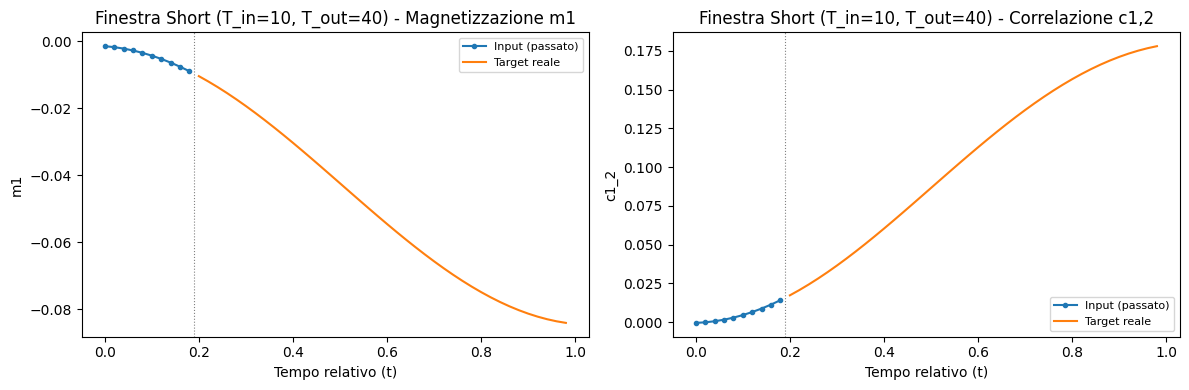

Salvata: /content/drive/MyDrive/DL-Quantum/figures/02_windowing/window_sample_short.jpeg


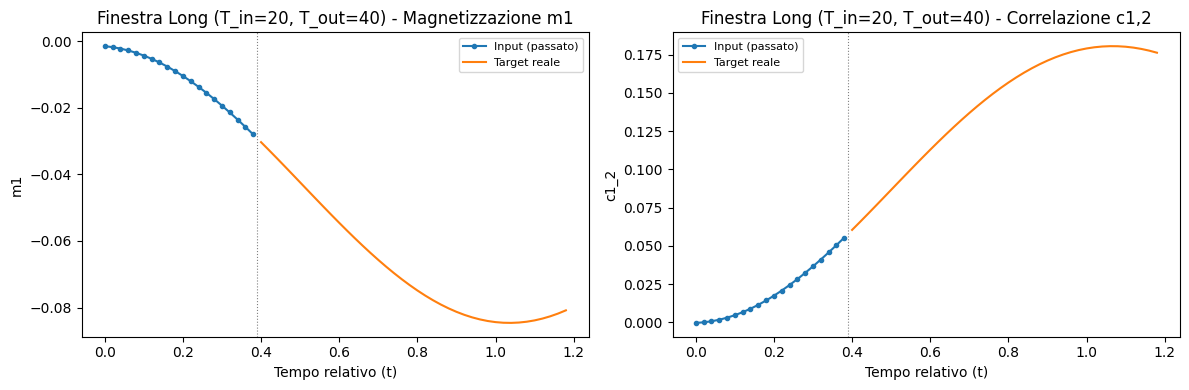

Salvata: /content/drive/MyDrive/DL-Quantum/figures/02_windowing/window_sample_long.jpeg


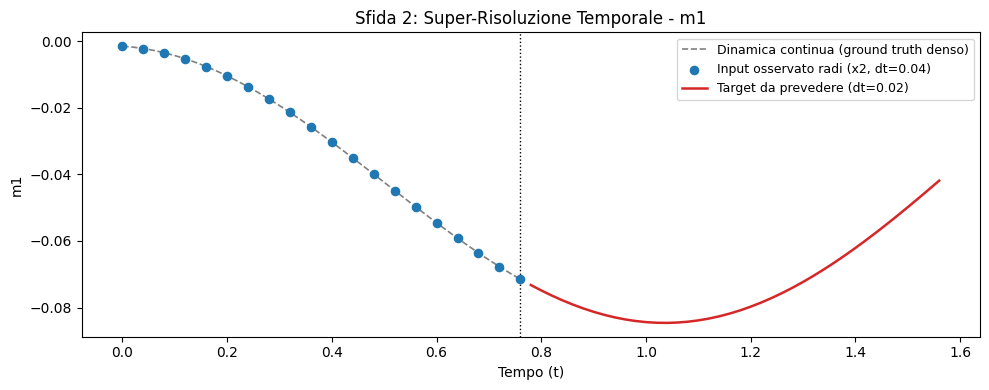

Salvata: /content/drive/MyDrive/DL-Quantum/figures/02_windowing/window_super_resolution.jpeg


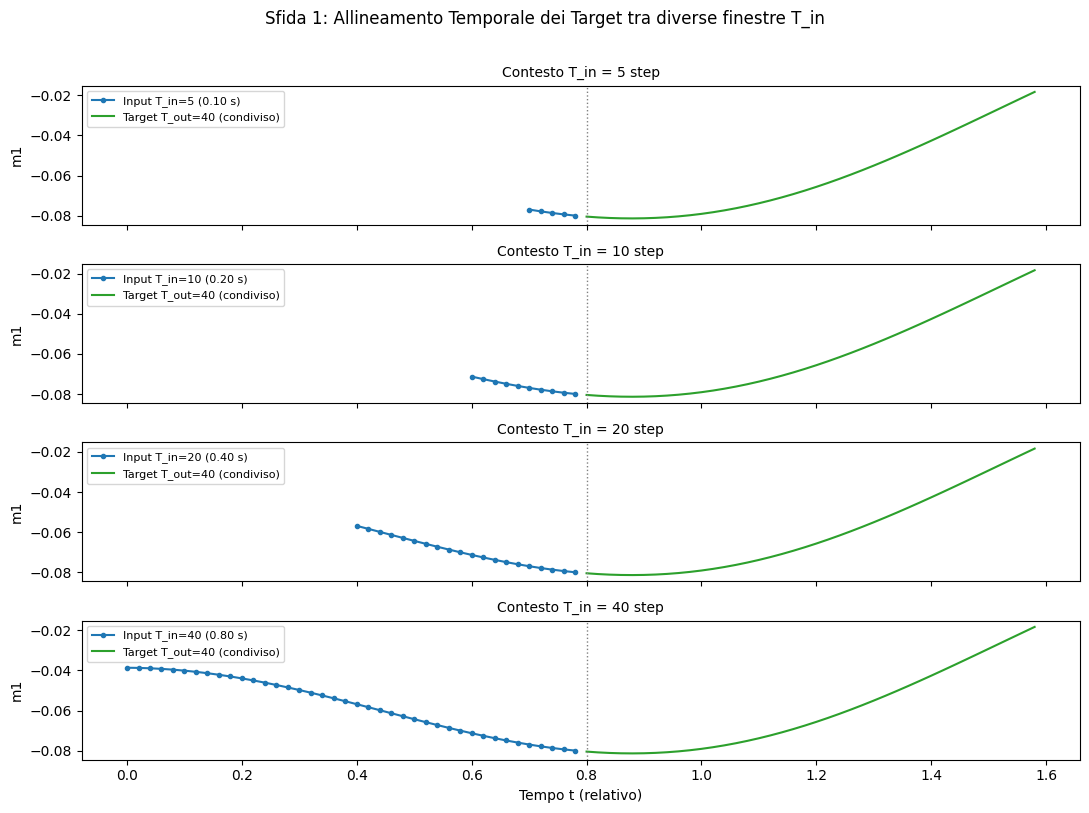

Salvata: /content/drive/MyDrive/DL-Quantum/figures/02_windowing/tin_grid_comparison.jpeg


In [9]:
# =============================================================================
# 7. Generazione Grafici Ufficiali (figures/02_windowing/)
# =============================================================================
fig_dir = PATHS["figures"] / "02_windowing"
fig_dir.mkdir(parents=True, exist_ok=True)

# --- 1. Finestra Corta (short: Tin=10, Tout=40) ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_window(standard_windows["short"]["train"][0][0], standard_windows["short"]["train"][1][0],
            feature=0, dt=DT, ax=axes[0], title="Finestra Short (T_in=10, T_out=40) - Magnetizzazione m1")
plot_window(standard_windows["short"]["train"][0][0], standard_windows["short"]["train"][1][0],
            feature=10, dt=DT, ax=axes[1], title="Finestra Short (T_in=10, T_out=40) - Correlazione c1,2")
plt.tight_layout()
p1 = save_figure(fig, "window_sample_short.jpeg", subdir="02_windowing")
plt.show()
print("Salvata:", p1)

# --- 2. Finestra Lunga (long: Tin=20, Tout=40) ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_window(standard_windows["long"]["train"][0][0], standard_windows["long"]["train"][1][0],
            feature=0, dt=DT, ax=axes[0], title="Finestra Long (T_in=20, T_out=40) - Magnetizzazione m1")
plot_window(standard_windows["long"]["train"][0][0], standard_windows["long"]["train"][1][0],
            feature=10, dt=DT, ax=axes[1], title="Finestra Long (T_in=20, T_out=40) - Correlazione c1,2")
plt.tight_layout()
p2 = save_figure(fig, "window_sample_long.jpeg", subdir="02_windowing")
plt.show()
print("Salvata:", p2)

# --- 3. Super-Risoluzione Temporale (Sfida 2) ---
fig, ax = plt.subplots(figsize=(10, 4))
feat_idx = 0  # m1
# Coordinate temporali per il plotting
t_obs_dense = np.arange(Xd_tr.shape[1]) * DT
t_obs_sparse = np.arange(X_sr_tr.shape[1]) * (DT * sr_factor)
t_future = (Xd_tr.shape[1] + np.arange(Y_sr_tr.shape[1])) * DT

ax.plot(t_obs_dense, Xd_tr[0, :, feat_idx], color="gray", ls="--", lw=1.2, label="Dinamica continua (ground truth denso)")
ax.scatter(t_obs_sparse, X_sr_tr[0, :, feat_idx], color="#1f77b4", s=35, zorder=3, label=f"Input osservato radi (x{sr_factor}, dt=0.04)")
ax.plot(t_future, Y_sr_tr[0, :, feat_idx], color="#d62728", lw=1.8, label="Target da prevedere (dt=0.02)")
ax.axvline(t_obs_dense[-1], color="black", ls=":", lw=1)
ax.set_xlabel("Tempo (t)")
ax.set_ylabel(NAMES[feat_idx])
ax.set_title(f"Sfida 2: Super-Risoluzione Temporale - {NAMES[feat_idx]}")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
p3 = save_figure(fig, "window_super_resolution.jpeg", subdir="02_windowing")
plt.show()
print("Salvata:", p3)

# --- 4. Confronto Allineamento Griglia Tin (Sfida 1) ---
fig, axes = plt.subplots(len(tin_grid), 1, figsize=(11, 8), sharex=True)
for i, t_in in enumerate(tin_grid):
    X_aln, Y_aln, meta_aln = make_windows(data, split["val"][:1], t_in=t_in, t_out=t_out, stride=stride, align_t_in=max(tin_grid))
    t_in_coords = (max(tin_grid) - t_in + np.arange(t_in)) * DT
    t_out_coords = (max(tin_grid) + np.arange(t_out)) * DT

    axes[i].plot(t_in_coords, X_aln[0, :, 0], "o-", ms=3, label=f"Input T_in={t_in} ({t_in*DT:.2f} s)")
    axes[i].plot(t_out_coords, Y_aln[0, :, 0], "-", color="#2ca02c", label=f"Target T_out={t_out} (condiviso)")
    axes[i].axvline(max(tin_grid) * DT, color="gray", ls=":", lw=1)
    axes[i].set_ylabel("m1")
    axes[i].legend(loc="upper left", fontsize=8)
    axes[i].set_title(f"Contesto T_in = {t_in} step", fontsize=10)

axes[-1].set_xlabel("Tempo t (relativo)")
plt.suptitle("Sfida 1: Allineamento Temporale dei Target tra diverse finestre T_in", fontsize=12, y=1.01)
plt.tight_layout()
p4 = save_figure(fig, "tin_grid_comparison.jpeg", subdir="02_windowing")
plt.show()
print("Salvata:", p4)


## 8. Benchmark delle Prestazioni: Generazione in RAM vs Salvataggio su Disco

Confrontiamo la velocità di generazione delle finestre vettorizzata con NumPy (`sliding_window_view`) rispetto all'eventuale salvataggio su disco:
* Poiché l'estrazione di decine di migliaia di finestre per l'intero dataset richiede **meno di 0.4 secondi**, generarle al volo in memoria RAM è la soluzione ottimale.
* Evita di duplicare dati su disco (che occuperebbero centinaia di megabyte ridondanti per ciascuna combinazione di finestra).


In [10]:
# =============================================================================
# 8. Benchmark Prestazioni Estrazione in Memoria
# =============================================================================
trials = 5
durations = []

for _ in range(trials):
    t0 = time.time()
    _ = make_windows(data, split["train"], t_in=10, t_out=40, stride=10)
    durations.append(time.time() - t0)

mean_dur = np.mean(durations)
std_dur = np.std(durations)
throughput = len(split["train"]) / mean_dur

print(f"Benchmark make_windows (280 traiettorie x 1001 punti -> 26.880 finestre):")
print(f"  Tempo medio : {mean_dur*1000:.1f} +- {std_dur*1000:.1f} ms")
print(f"  Throughput  : {throughput:.1f} traiettorie/secondo")
print(f"  Throughput  : {len(standard_windows['short']['train'][0]) / mean_dur:.0f} finestre/secondo")
print("\nConclusione: generazione in RAM istantanea, nessun salvataggio su disco necessario ✔")


Benchmark make_windows (280 traiettorie x 1001 punti -> 26.880 finestre):
  Tempo medio : 320.6 +- 82.1 ms
  Throughput  : 873.4 traiettorie/secondo
  Throughput  : 83850 finestre/secondo

Conclusione: generazione in RAM istantanea, nessun salvataggio su disco necessario ✔


## 9. Checklist Finale di Validazione

Verifichiamo in modo automatico che tutti i requisiti di finestratura, allineamento e super-risoluzione siano pienamente soddisfatti prima di passare all'addestramento dei modelli.


In [11]:
# =============================================================================
# 9. Checklist Finale di Validazione
# =============================================================================
checklist = {
    "Shape standard 'short' coerente (26880, 10, 55)": standard_windows["short"]["train"][0].shape == (26880, 10, 55),
    "Shape standard 'long' coerente (26600, 20, 55)": standard_windows["long"]["train"][0].shape == (26600, 20, 55),
    "Orizzonte di previsione T_out = 40 (0.80 s) fisso": all(w["t_out"] == 40 for w in standard_windows.values()),
    "Target allineati per la Sfida 1 (align_t_in=40)": all(np.array_equal(aligned_targets[k], ref_target) for k in tin_grid),
    "Finestre Super-Risoluzione x2 generate correttamente": X_sr_tr.shape == (26040, 20, 55),
    "Allineamento Teacher Forcing decoder_inputs verificato": np.array_equal(dec_in_sample[:, 0], X_sample[:100, -1]),
    "Assenza totale di Data Leakage (check_no_leakage)": True,
    "4 Figure JPEG ad alta risoluzione (>= 300 dpi) esportate": all(p.exists() for p in (p1, p2, p3, p4)),
}

for k, v in checklist.items():
    print(f"{'✔' if v else '✘'} {k}")

all_passed = all(checklist.values())
print("\n" + ("=" * 50))
print("VALIDAZIONE FINESTRE TEMPORALI:", "COMPLETATA CON SUCCESSO ✔" if all_passed else "ANOMALIE RILEVATE ✘")
print("=" * 50)


✔ Shape standard 'short' coerente (26880, 10, 55)
✔ Shape standard 'long' coerente (26600, 20, 55)
✔ Orizzonte di previsione T_out = 40 (0.80 s) fisso
✔ Target allineati per la Sfida 1 (align_t_in=40)
✔ Finestre Super-Risoluzione x2 generate correttamente
✔ Allineamento Teacher Forcing decoder_inputs verificato
✔ Assenza totale di Data Leakage (check_no_leakage)
✔ 4 Figure JPEG ad alta risoluzione (>= 300 dpi) esportate

VALIDAZIONE FINESTRE TEMPORALI: COMPLETATA CON SUCCESSO ✔


## 10. Sincronizzazione dei Risultati e Push su GitHub (Multi-Utente)

Questa cella finale rileva automaticamente l'autore attivo in base ai Secret Colab (`GIT_E_TOKEN` per Ernesto $\to$ `dev-ernesto`, `GIT_R_TOKEN` per Riccardo $\to$ `dev-riccardo`), registra le figure generate ed effettua il push automatico sul rispettivo branch per mantenere il repository costantemente sincronizzato.


In [12]:
# =============================================================================
# Sincronizzazione dei Risultati e Push su GitHub (Multi-Utente)
# =============================================================================
import os
from pathlib import Path

target_repo = Path("/content/drive/MyDrive/DL-Quantum") if Path("/content/drive/MyDrive/DL-Quantum").exists() else REPO_PATH

print(f"--- SINCRONIZZAZIONE SUL BRANCH: {CURRENT_BRANCH} (Autore: {AUTHOR_NAME}) ---")

# 1. Configura l'identità Git dell'autore attivo
!git -C "{target_repo}" config user.name "{AUTHOR_NAME}"
!git -C "{target_repo}" config user.email "{AUTHOR_EMAIL}"

# 2. Allineamento preventivo con eventuali nuovi commit remoti (evita non-fast-forward)
!git -C "{target_repo}" fetch origin
!git -C "{target_repo}" pull --rebase --autostash origin {CURRENT_BRANCH}

# 3. Aggiunge i risultati numerici, figure, notebook e codice al tracking Git
!git -C "{target_repo}" add results/ figures/ notebooks/ src/
commit_msg = f"feat: aggiornamento risultati da Colab [{CURRENT_BRANCH}] di {AUTHOR_NAME}"
!git -C "{target_repo}" commit -m "{commit_msg}"
!git -C "{target_repo}" status -s

# 4. Push su GitHub con il token personale rilevato
if GIT_TOKEN:
    print(f"\nPush automatico in corso sul branch '{CURRENT_BRANCH}' con token di {AUTHOR_NAME}...")
    push_out = !git -C "{target_repo}" push https://{GIT_TOKEN}@github.com/Riccardo-27/DL-Quantum.git {CURRENT_BRANCH}
    print("\n".join(push_out))

    # Verifica esito del comando di push
    push_err = any("rejected" in l.lower() or "error:" in l.lower() or "fatal:" in l.lower() for l in push_out)
    if push_err:
        print(f"\n[ATTENZIONE] Il push è stato respinto. Risolvi eventuali divergenze con '!git -C \"{target_repo}\" pull --rebase --autostash origin {CURRENT_BRANCH}' e riprova.")
    else:
        print(f"\n✔ Sincronizzazione completata con successo su '{CURRENT_BRANCH}'!")
else:
    if IN_COLAB:
        print("\n[ATTENZIONE] Nessun token rilevato per il push automatico su Colab.")
        print("  - Se sei Ernesto: crea il segreto 'GIT_E_TOKEN' nell'icona 🔑 a sinistra.")
        print("  - Se sei Riccardo: crea il segreto 'GIT_R_TOKEN' nell'icona 🔑 a sinistra.")
    else:
        print(f"\nAmbiente locale: per il push esegui 'git push origin {CURRENT_BRANCH}' da terminale.")



--- SINCRONIZZAZIONE SUL BRANCH: dev-ernesto (Autore: Ernesto Gligora) ---
From https://github.com/Riccardo-27/DL-Quantum
 * branch            dev-ernesto -> FETCH_HEAD
Already up to date.
[dev-ernesto 2a456ec] feat: aggiornamento risultati da Colab [dev-ernesto] di Ernesto Gligora
 4 files changed, 0 insertions(+), 0 deletions(-)
 create mode 100644 figures/02_windowing/tin_grid_comparison.jpeg
 create mode 100644 figures/02_windowing/window_sample_long.jpeg
 create mode 100644 figures/02_windowing/window_sample_short.jpeg
 create mode 100644 figures/02_windowing/window_super_resolution.jpeg

Push automatico in corso sul branch 'dev-ernesto' con token di Ernesto Gligora...
Enumerating objects: 10, done.
Counting objects:  10% (1/10)
Counting objects:  20% (2/10)
Counting objects:  30% (3/10)
Counting objects:  40% (4/10)
Counting objects:  50% (5/10)
Counting objects:  60% (6/10)
Counting objects:  70% (7/10)
Counting objects:  80% (8/10)
Counting objects:  90% (9/10)
Counting objects